---

title: "Demographic Changes in GUDD dataset"
author: "Juan F. Martinez"

---


The Global Urban Demographic Dataset (GUDD), version 1 provides a comprehensive overview of demographic changes in urban areas worldwide. This analysis focuses on the key trends observed in Gudd, highlighting shifts in population size, age distribution, and migration patterns over the past two decades.

In this tutorial, we will explore demographic changes in dependency ratios--including youg and old dependency ratios-- male-female ratios in young, working and elderly populations, and their implications for urban planning and policy-making. We will also examine how age-sex pyramid structures have evolved in Gudd, providing insights into the changing needs of the population.


We will use Python to analyze the data, leveraging libraries such as pandas for data manipulation and matplotlib for visualization. The analysis will include:

- Downloading and working with the GUDD dataset
- Using geoparquet static boundaries to determine temporal changes in demographic characteristics
- Visualizing changes in age-sex pyramids and dependency ratios
- Interpreting the results to inform urban planning and policy decisions


## Downloading the GUDD Dataset

THe GUDD dataset was developed by Andrew Zimmer, Nina Brooks, Andrea E. Gaughan & Cascade Tuholske. Their work can be cited as follows: 

Zimmer, A., Brooks, N., Gaughan, A.E. et al. Global divergence in urban demographic change and migration patterns. Nat Cities 3, 599–607 (2026). [https://doi.org/10.1038/s44284-026-00447-7](https://doi.org/10.1038/s44284-026-00447-7)

The GUDD dataset is available for download from the Harvard Dataverse. You can access the dataset using the following link: [GUDD Dataset](https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/GMV8WG).

We will use the gudd_static_boundaries_lookup.geoparquet file as a reference for the static boundaries of Gudd, which will help us analyze demographic changes over time. Using the static boundaries, we can control for spatial variations and focus on temporal changes in demographic characteristics.

The geoparquet file contains the spatial geometries of the static boundaries, as well as a year field and an ID field that can be used to link the boundaries to the demographic data. Since the boudnaries are static, the year field will be the same for all records, but it is important to note that the demographic data may vary over time. We will use the ID field to link the static boundaries to the demographic data in the GUDD dataset.

Download the CSV file `gudd_all_static_boundaries.csv` that contains raw population counts for each age-sex cohort, derived using static boundaries. The CSV file is also available from the Harvard Dataverse.  


## Working with the GUDD Dataset

First, we will load the GUDD CSV file into a pandas DataFrame. We will then explore the dataset to understand its structure and contents. The GUDD dataset contains information about population counts for different age-sex cohorts, which will be used to analyze demographic changes over time.



### Building the Age-Sex Pyramids for a country of interest

We can start by working with the GUDD all static boundaries CSV, which provides 5-year age groups and sex-specific population data. This data will be used to create age-sex pyramids that visualize the demographic structure of the population over time.

Let's load the GUDD CSV file into a pandas DataFrame and preview the table columns and head. We will also check for any missing values in the dataset.



In [5]:
import pandas as pd

# define the path to the GUDD CSV file
gudd_all_csv_path = r"D:\jmartine\user_guides\gudd\gudd_all_static_boundaries.csv"

# load the GUDD CSV file into a pandas DataFrame
gudd_all_data = pd.read_csv(gudd_all_csv_path)

# preview the table columns and head

print(gudd_all_data.columns) 

Index(['ID_UC_G0', 'year', 'f_00', 'f_01', 'f_05', 'f_10', 'f_15', 'f_20',
       'f_25', 'f_30', 'f_35', 'f_40', 'f_45', 'f_50', 'f_55', 'f_60', 'f_65',
       'f_70', 'f_75', 'f_80', 'm_00', 'm_01', 'm_05', 'm_10', 'm_15', 'm_20',
       'm_25', 'm_30', 'm_35', 'm_40', 'm_45', 'm_50', 'm_55', 'm_60', 'm_65',
       'm_70', 'm_75', 'm_80', 'Name', 'Country', 'Continent', 'Development',
       'YearOfBirth', 'YearOfDeath', 'latitude', 'longitude'],
      dtype='str')


According to the GUDD readme file, the dataset contains columns for irregular age groups for Ages <1 and 1-4. All other age groups are in 5-year intervals, up to 80+. The dataset also includes columns for sex-specific population counts, as well as total population counts for each age group.

We can combine the irregular age groups into a single age group of 0-4, and then create a new column for the 5-year age groups. This will allow us to create age-sex pyramids that are consistent across all age groups.

In [6]:
## add a new column that sums f_00 and f_01, and m_00 and m_01, to create a new age group of 0-4
gudd_all_data['f_0_4'] = gudd_all_data['f_00'] + gudd_all_data['f_01']
gudd_all_data['m_0_4'] = gudd_all_data['m_00'] + gudd_all_data['m_01']

Now that our data is prepared we can create a function to generate age-sex pyramids by inputting the country and years of interest as required parameters.

These visualizations will help us understand how the population structure has changed over time, providing insights into demographic trends and potential implications for urban planning and policy-making.

To visualize the age-sex pyramids, we will use the `matplotlib` and `numpy` libraries to create bar charts that represent the population counts for each age-sex cohort. The x-axis will represent the population counts, while the y-axis will represent the age groups. We will create separate bars for males and females, allowing us to compare the population distribution between the two sexes.

In [15]:

import matplotlib.pyplot as plt
import numpy as np



## select columns of interest for age-sex cohorts

f_age_sex_columns = ['f_0_4', 'f_05', 'f_10', 'f_15', 
                     'f_20', 'f_25', 'f_30', 'f_35', 
                     'f_40', 'f_45', 'f_50', 'f_55', 
                     'f_60', 'f_65', 'f_70', 'f_75', 'f_80']

m_age_sex_columns = ['m_0_4', 'm_05', 'm_10', 'm_15', 
                     'm_20', 'm_25', 'm_30', 'm_35', 
                     'm_40', 'm_45', 'm_50', 'm_55', 
                     'm_60', 'm_65', 'm_70', 'm_75', 'm_80']
 
 

# Age group labels
age_groups = [
    '0-4', '5-9', '10-14', '15-19', '20-24',
    '25-29', '30-34', '35-39', '40-44', '45-49',
    '50-54', '55-59', '60-64', '65-69', '70-74',
    '75-79', '80+'
]

 

def plot_population_pyramid(df, country, year1=2000, year2=2020):

   
    # Filter country
    country_df = df[df['Country'] == country]

    # Get observations for each year
    data1 = country_df[country_df['year'] == year1]
    data2 = country_df[country_df['year'] == year2]

    if data1.empty or data2.empty:
        raise ValueError(
            f"Missing data for {country} in {year1} or {year2}"
        )

    # Extract population values
    # Assumes one row per country/year
    data1 = data1.iloc[0]
    data2 = data2.iloc[0]

    m1 = data1[m_age_sex_columns].to_numpy(dtype=float)[::-1]
    f1 = data1[f_age_sex_columns].to_numpy(dtype=float)[::-1]

    m2 = data2[m_age_sex_columns].to_numpy(dtype=float)[::-1]
    f2 = data2[f_age_sex_columns].to_numpy(dtype=float)[::-1]

    # Reverse age labels
    age_labels = age_groups[::-1]
    y = np.arange(len(age_labels))

    # Create figure
    fig, ax = plt.subplots(figsize=(12, 9))

    # Year 1 - lighter colors
    ax.barh(
        y, -m1,
        color='#A9C9E8',
        label=f'Male {year1}',
        height=0.8,
        edgecolor='white'
    )

    ax.barh(
        y, f1,
        color='#F2B6C2',
        label=f'Female {year1}',
        height=0.8,
        edgecolor='white'
    )

    # Year 2 - darker colors
    ax.barh(
        y, -m2,
        color='#27699E',
        label=f'Male {year2}',
        height=0.4
    )

    ax.barh(
        y, f2,
        color='#C84D70',
        label=f'Female {year2}',
        height=0.4
    )

    # Center line
    ax.axvline(0, color='black', linewidth=0.8)

    # Labels
    ax.set_yticks(y)
    ax.set_yticklabels(age_labels)
    ax.set_ylabel('Age group')
    ax.set_xlabel('Population')

    # Symmetric horizontal scale
    max_population = np.nanmax([m1, f1, m2, f2])

    ax.set_xlim(
        -max_population * 1.1,
        max_population * 1.1
    )

    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f'{abs(x):,.0f}')
    )

    ax.set_title(
        f'Population Pyramid: {country} ({year1} vs. {year2})',
        fontsize=16,
        fontweight='bold'
    )

    ax.grid(axis='x', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)

    ax.legend(
        loc='lower center',
        bbox_to_anchor=(0.5, -0.13),
        ncol=4,
        frameon=False
    )

    plt.tight_layout()
    plt.show()




Now we can use this function to create age-sex pyramids for the years 2000 and 2020 allowing us to select a country of interest. The function will take the DataFrame, country name, and years as input parameters, and will generate the age-sex pyramids for the specified years.

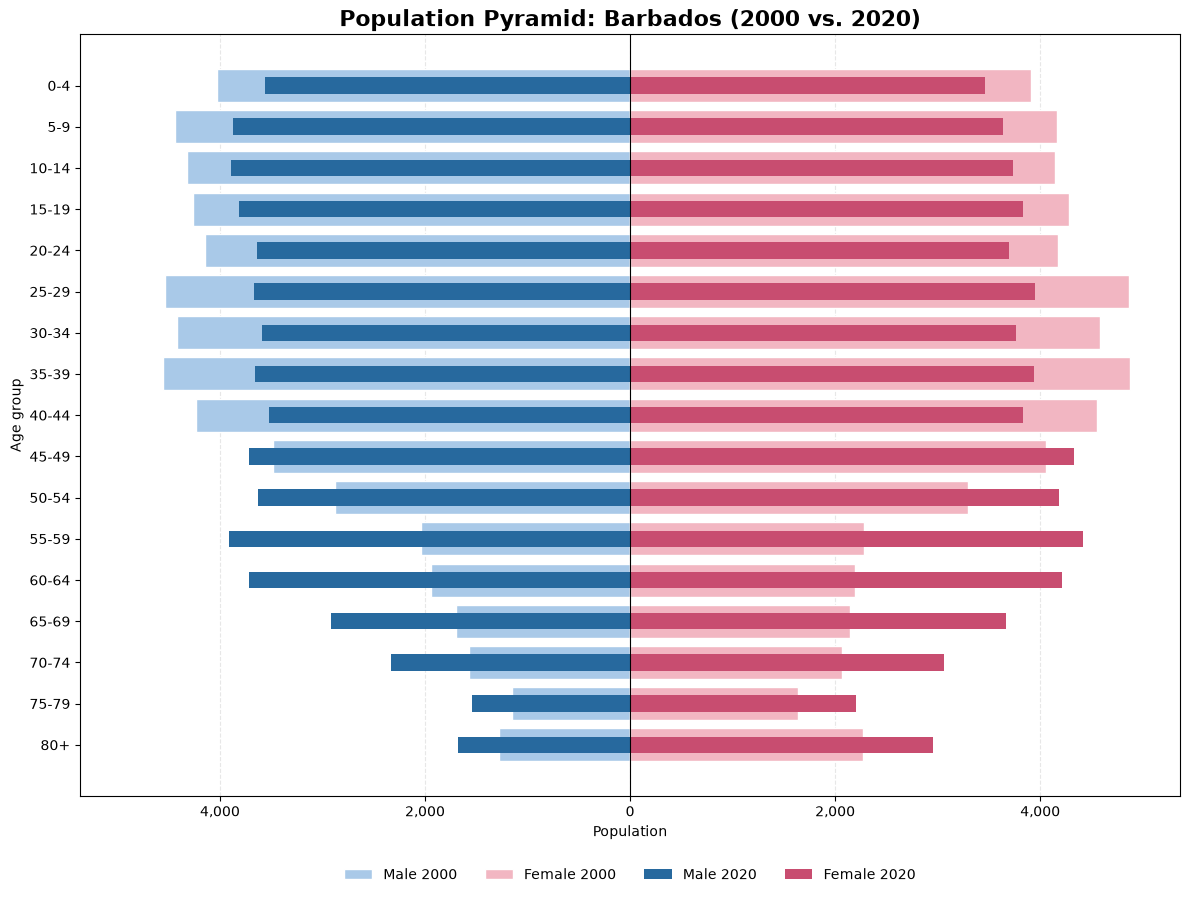

In [16]:
plot_population_pyramid(
    gudd_all_data,
    country='Barbados',
    year1=2000,
    year2=2020
)

What are some of the changes in the age-sex pyramids for the country of interest between 2000 and 2020? How do these changes reflect broader demographic trends in the country, and what implications might they have for urban planning and policy-making?

## Demographic Changes in GUDD Dataset from 2000 to 2020

We can start by working with the GUDD tabular data that contains demographic changes between 2000 and 2020. The CSV file `gudd_change_2000_2020_static_boundaries.csv` is used to analyze the changes in population counts for each age-sex cohort over the two decades. We will load this CSV file into a pandas DataFrame and preview its columns and head to understand its structure.

# <font color="RED">Hello</font> <font color="PURPLE">CATTLEYA </font> <font color="LIGHTBLUE">MIA</font> <font color="BLACK">SCIORTINO</font>

In [17]:


# define the path to the GUDD CSV file
gudd_change_csv_path = r"D:\jmartine\user_guides\gudd\gudd_change_2000_2020_static_boundaries.csv"

# load the GUDD CSV file into a pandas DataFrame
gudd_change_data = pd.read_csv(gudd_change_csv_path)

# preview the table columns and head

print(gudd_change_data.columns) 

Index(['index', 'young_pop_Delta', 'working_pop_Delta', 'old_pop_Delta',
       'total_pop_Delta', 'total_dr_Delta', 'young_dr_Delta', 'old_dr_Delta',
       'women_cba_Delta', 'women_cr_Delta', 'young_sr_Delta',
       'working_sr_Delta', 'old_sr_Delta', 'total_sr_Delta',
       'general_fr_Delta', 'ID_UC_G0', 'year', 'sum_births', 'sum_deaths',
       'natural_change', 'total_migration', 'total_pop_2020',
       'perc_from_migration', 'Name', 'Country', 'Continent', 'Development',
       'YearOfBirth', 'YearOfDeath', 'latitude', 'longitude'],
      dtype='str')


### Changes in Dependency Ratios by Continent

With this information, we can analyze changes in dependency ratios, male-female ratios, and other demographic characteristics over the two decades. This analysis will provide insights into the changing needs of the population and inform urban planning and policy decisions. 

Lets first determine on average how dependency ratios for total, young and old populations have changed between 2000 and 2020 over each continent. 

In [24]:
# Dependency ratio change columns
dependency_columns = [
    'total_dr_Delta',
    'young_dr_Delta',
    'old_dr_Delta'
]

# Calculate mean change by continent
continent_changes = (
    gudd_change_data
    .groupby('Continent')[dependency_columns]
    .mean()
    .round(3)
)

# sort by total_dr_Delta in descending order
continent_changes = continent_changes.sort_values(by='total_dr_Delta', ascending=False)

print(continent_changes)

                                  total_dr_Delta  young_dr_Delta  old_dr_Delta
Continent                                                                     
Europe                                     0.061          -0.011         0.072
Australia and New Zealand                  0.047          -0.018         0.065
Northern America                           0.029          -0.040         0.069
Eastern and South-Eastern Asia            -0.049          -0.118         0.068
Sub-Saharan Africa                        -0.069          -0.072         0.003
Oceania                                   -0.100          -0.123         0.024
Northern Africa and Western Asia          -0.121          -0.137         0.016
Latin America and the Caribbean           -0.131          -0.170         0.039
Central and Southern Asia                 -0.157          -0.178         0.022


What can the changing dependency ratios tell us about the demographic trends in each continent, and how might these trends impact urban planning and policy-making in the future?

### Changes in sex ratios by continent

Similarly, we can analyze changes in sex ratios for total, young, working and elderly populations over the two decades. 



In [23]:
# sex ratio change columns
sex_ratio_columns = [
    'young_sr_Delta', 'working_sr_Delta', 'old_sr_Delta', 'total_sr_Delta',
]

# Calculate mean change by continent
continent_changes_sr = (
    gudd_change_data
    .groupby('Continent')[sex_ratio_columns]
    .mean()
    .round(3)
)

# sort by total_sr_Delta in descending order
continent_changes_sr = continent_changes_sr.sort_values(by='total_sr_Delta', ascending=False)

print(continent_changes_sr)

                                  young_sr_Delta  working_sr_Delta  \
Continent                                                            
Northern Africa and Western Asia           0.001             0.016   
Central and Southern Asia                  0.012             0.007   
Oceania                                    0.002             0.003   
Sub-Saharan Africa                        -0.004            -0.005   
Australia and New Zealand                 -0.002            -0.002   
Europe                                     0.003            -0.006   
Latin America and the Caribbean           -0.002            -0.002   
Northern America                          -0.000            -0.004   
Eastern and South-Eastern Asia             0.002             0.003   

                                  old_sr_Delta  total_sr_Delta  
Continent                                                       
Northern Africa and Western Asia         0.000           0.015  
Central and Southern Asia         

What can the changing sex ratios tell us about the demographic trends in each continent, and how might these trends impact urban planning and policy-making in the future?

### Visualizing Demographic Changes

To open a geoparquet file in Python, we can use the `geopandas` library. First, we need to install the library if it is not already installed. We also define the path to the `gudd_static_boundaries_lookup.geoparquet` file, which contains the static boundaries for Gudd:

In [25]:
import geopandas as gpd

#define the path to the static boundaries file
boundaries_path = r"D:\jmartine\user_guides\gudd\gudd_static_boundaries_lookup.geoparquet"

# open the geoparquet file using geopandas
gudd_boundaries = gpd.read_parquet(boundaries_path)


Once we have loaded the static boundaries, we can explore the dataset to understand its structure and contents. The `gudd_boundaries` GeoDataFrame contains information about the geographic boundaries of Gudd, which will be used to analyze demographic changes over time.

Let's start with visualizing the static boundaries of Gudd to get a better understanding of the area we are analyzing. We can use the `plot` method from `matplotlib` and `geopandas` to create a simple map of the static boundaries.

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

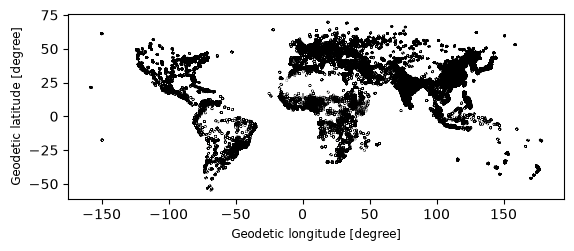

In [26]:

# Visualize the static boundaries of Gudd with a thick border line

gudd_boundaries.plot(edgecolor='black', linewidth=2)


Now we can view the tabular data of the static boundaries to see the attributes associated with each boundary. This will help us understand the demographic characteristics of Gudd and how they have changed over time.

In [27]:
#view the column names of the static boundaries
print(gudd_boundaries.columns)

# view the tabular data of the static boundaries
print(gudd_boundaries.head())

Index(['ID_UC_G0', 'geometry', 'boundary_year'], dtype='str')
   ID_UC_G0                                           geometry  boundary_year
0         4  POLYGON ((-149.52669 -17.5341, -149.51641 -17....           2020
1         5  POLYGON ((-117.03785 32.38735, -117.04893 32.3...           2020
2         6  POLYGON ((-123.27621 48.47642, -123.28911 48.4...           2020
3         7  POLYGON ((-92.04622 14.91363, -92.03603 14.913...           2020
4         8  POLYGON ((-89.84828 13.9475, -89.83812 13.9475...           2020


With the `ID_UC_G0` column, we can link the static boundaries to the demographic data in the GUDD dataset. This will allow us to analyze changes in population counts for each age-sex cohort over time, providing insights into demographic trends and potential implications for urban planning and policy-making.

### Visualizing changes in dependency ratios and sex ratios

We can use the tabular data of demographic changes to visualize changes in dependency ratios and sex ratios over the two decades. This will help us understand how the population structure has evolved and what implications it may have for urban planning and policy-making.

First, we append both tables to the geopandas dataframe of static boundaries, allowing us to visualize the changes in dependency ratios and sex ratios on a map. We can use the `plot` method from `matplotlib` and `geopandas` to create maps that show the changes in dependency ratios and sex ratios for each continent.

In [30]:
## join the static boundaries with the dependency ratio changes by city using the ID_UC_G0 column as the key
gudd_boundaries_with_changes = gudd_boundaries.merge(
    gudd_change_data, on='ID_UC_G0', how='left'
)

gudd_boundaries_with_changes.columns

Index(['ID_UC_G0', 'geometry', 'boundary_year', 'index', 'young_pop_Delta',
       'working_pop_Delta', 'old_pop_Delta', 'total_pop_Delta',
       'total_dr_Delta', 'young_dr_Delta', 'old_dr_Delta', 'women_cba_Delta',
       'women_cr_Delta', 'young_sr_Delta', 'working_sr_Delta', 'old_sr_Delta',
       'total_sr_Delta', 'general_fr_Delta', 'year', 'sum_births',
       'sum_deaths', 'natural_change', 'total_migration', 'total_pop_2020',
       'perc_from_migration', 'Name', 'Country', 'Continent', 'Development',
       'YearOfBirth', 'YearOfDeath', 'latitude', 'longitude'],
      dtype='str')

Now that we have joined the static boundaries with the demographic changes, we can create visualizations to show how dependency ratios and sex ratios have changed over time. This will help us understand the demographic trends in each continent and inform urban planning and policy-making decisions.

Since this is a global dataset, it would be difficut to visualize the polygons of each city, so we first use the cities centroids to visualizr the changes in demographic characteristics. We can calculate the centroids of the static boundaries using the `centroid` attribute of the GeoDataFrame, and then create a new GeoDataFrame containing the centroids and the demographic changes.

In [48]:
# Calculate city centroids
gudd_centroids = gudd_boundaries_with_changes.copy()
gudd_centroids['geometry'] = gudd_centroids.geometry.centroid

C:\Users\jfm2205\AppData\Local\Temp\28\ipykernel_32540\3017896661.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gudd_centroids['geometry'] = gudd_centroids.geometry.centroid


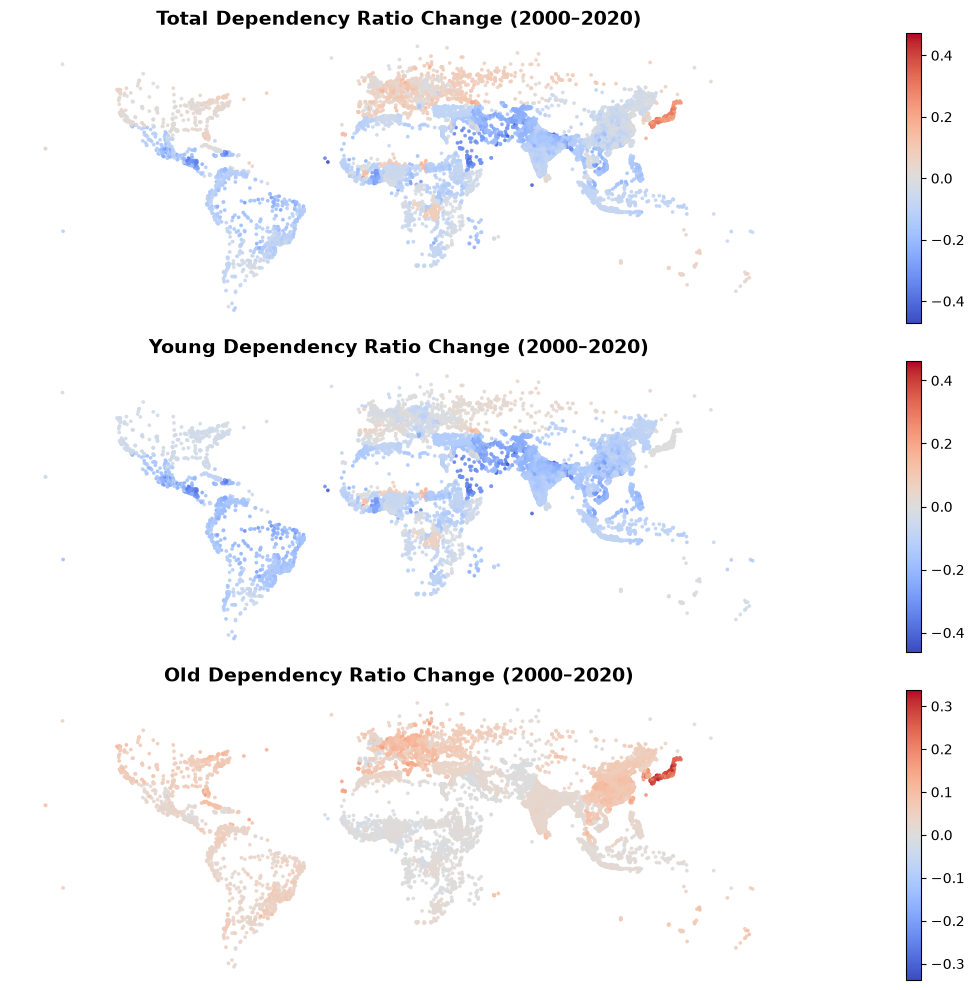

In [84]:
# plot the static boundaries with the dependency ratio changes 


import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# Variables to plot
variables = [
    'total_dr_Delta',
    'young_dr_Delta', 
    'old_dr_Delta'
]

# Map titles
titles = [
    'Total Dependency Ratio Change (2000–2020)',
    'Young Dependency Ratio Change (2000–2020)',
    'Old Dependency Ratio Change (2000–2020)', 
]

# Create 2x2 subplot layout
fig, axes = plt.subplots(3,1, figsize=(24, 10))

# Plot each variable
for variable, title, ax in zip(variables, titles, axes.flatten()):

    # Calculate symmetric color scale
    max_abs = gudd_centroids[variable].abs().max()

    # Plot centroids
    gudd_centroids.plot(
        column=variable,
        cmap='coolwarm',
        norm=TwoSlopeNorm(vmin=-max_abs, vcenter=0, vmax=max_abs),
        markersize=3,
        legend=True,
        ax=ax,
        alpha=0.8
    )

    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_axis_off()

plt.tight_layout()
plt.show()

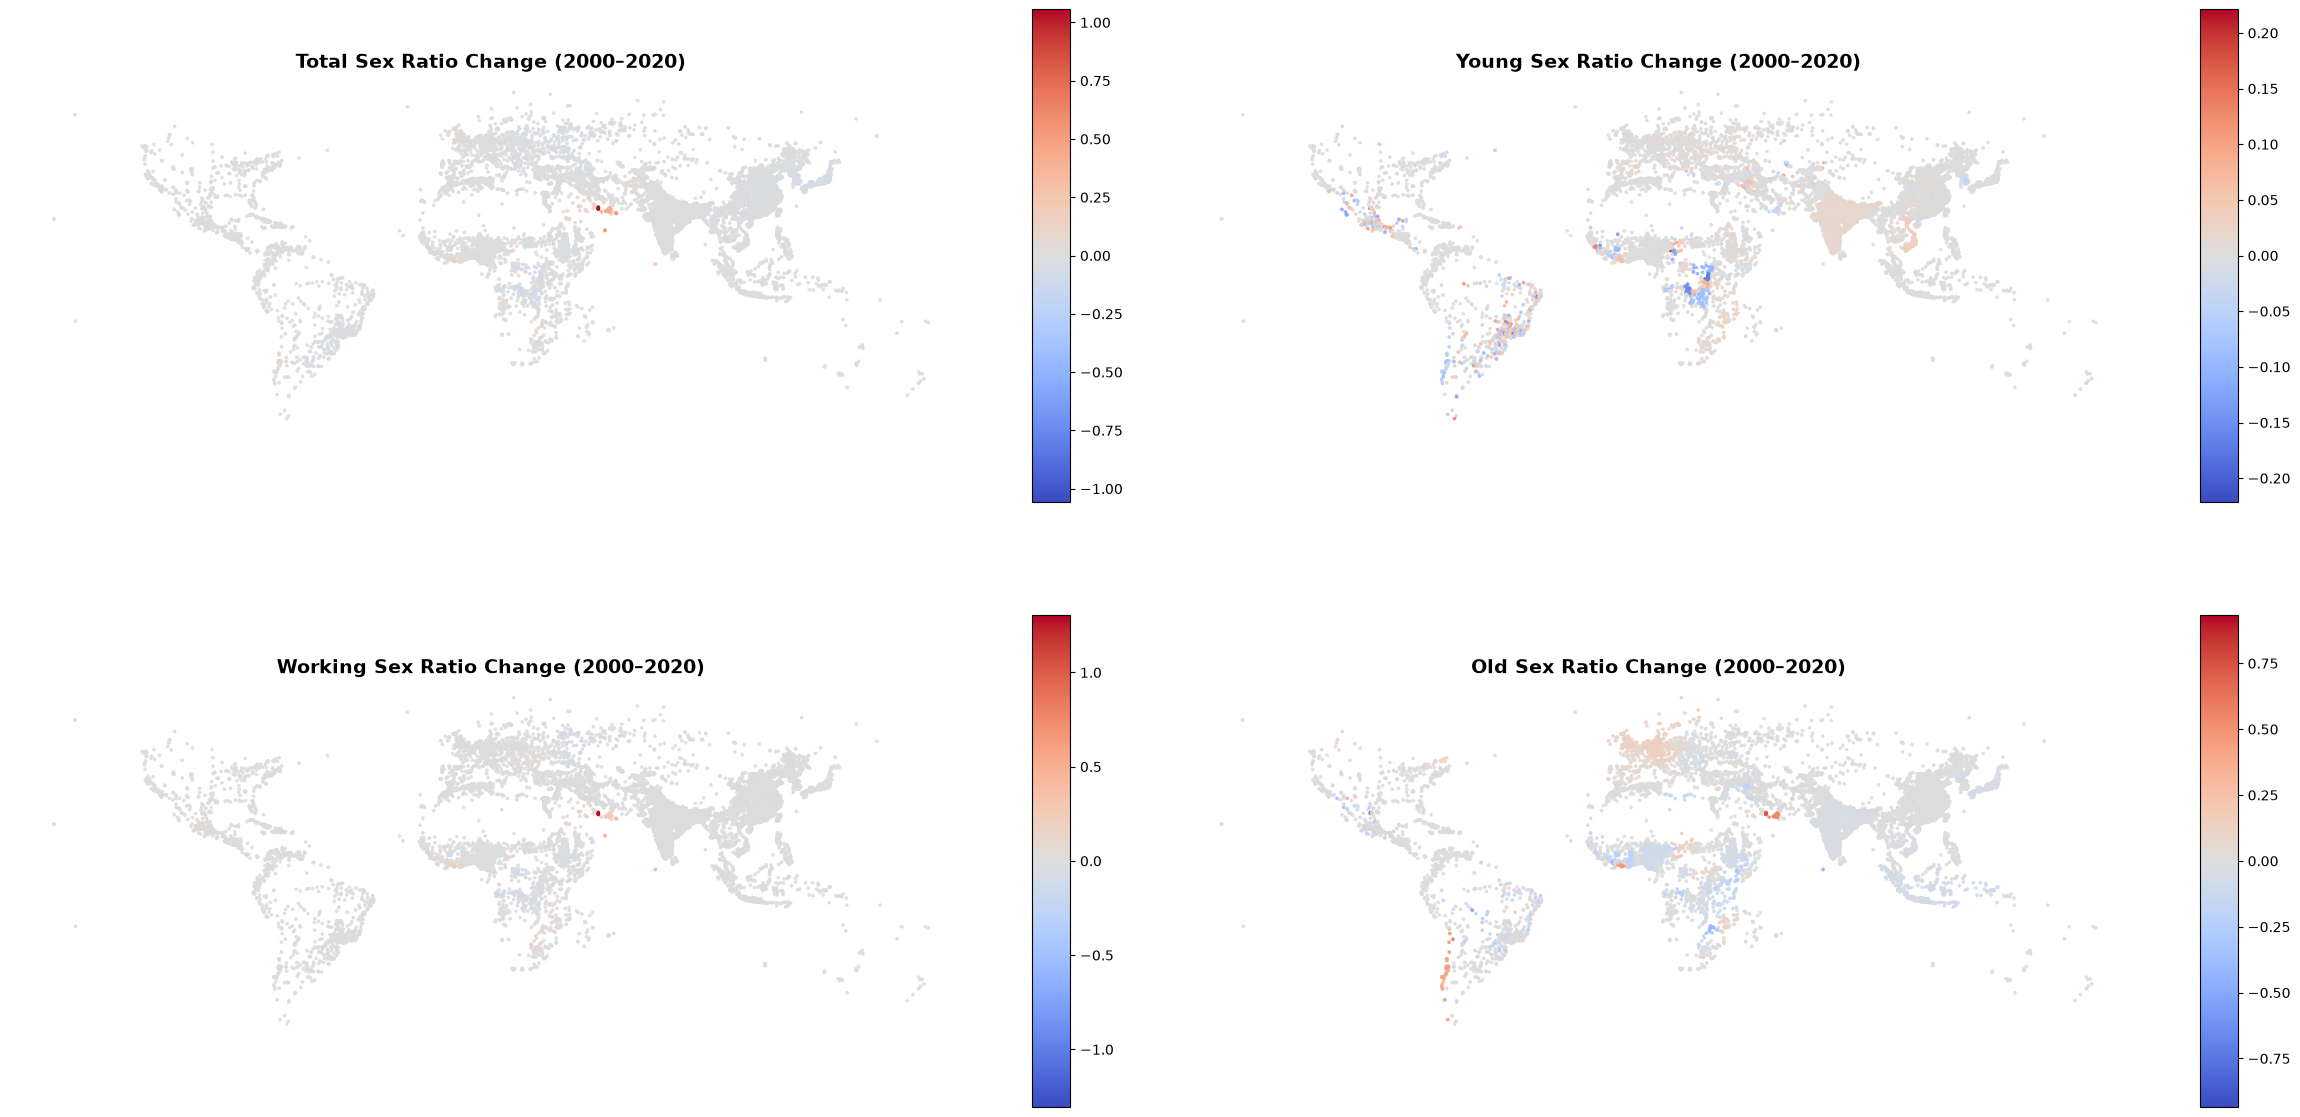

In [87]:
# plot the static boundaries with the sex ratio changes
 

# Variables to plot
variables = [
    'total_sr_Delta',
    'young_sr_Delta',
    'working_sr_Delta',
    'old_sr_Delta'
]

# Map titles
titles = [
    'Total Sex Ratio Change (2000–2020)',
    'Young Sex Ratio Change (2000–2020)',
    'Working Sex Ratio Change (2000–2020)',
    'Old Sex Ratio Change (2000–2020)'
]

# Create 2x2 subplot layout
fig, axes = plt.subplots(2, 2, figsize=(24, 14))

# Plot each variable
for variable, title, ax in zip(variables, titles, axes.flatten()):

    # Calculate symmetric color scale
    max_abs = gudd_centroids[variable].abs().max()

    # Plot centroids
    gudd_centroids.plot(
        column=variable,
        cmap='coolwarm',
        norm=TwoSlopeNorm(vmin=-max_abs, vcenter=0, vmax=max_abs),
        markersize=3,
        legend=True,
        ax=ax,
        alpha=0.8
    )

    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_axis_off()

plt.tight_layout()
plt.show()

What do the visualizations of changes in dependency ratios and sex ratios tell us about the demographic trends in cities around the world, and how might these trends impact urban planning and policy-making in the future?

## Conclusion and Discussion

Using the GUDD dataset, we have analyzed demographic changes in urban areas worldwide between 2000 and 2020. By examining changes in dependency ratios, sex ratios, and age-sex pyramids, we have gained insights into the evolving population structure and its implications for urban planning and policy-making at a global scale. 

This dataset provides a valuable resource for researchers, policymakers, and urban planners to understand demographic trends and make informed decisions that address the needs of the population.

For more information on the GUDD dataset, please refer to the original publication by Zimmer et al. (2026) and the Harvard Dataverse repository where the dataset is hosted.

This tutorial was produced by CIESIN at Columbia University, 2026. 

All materials used and produced by CIESIN are licensed under a Creative Commons Attribution 4.0 International License (CC BY 4.0).